### Problem 19 : The method zoo - fourteen ways to forget, one exam

⏱️ ~50 min · 🧭 Stage 8 (Extensions), rung 13 · 📄 `resources/papers/03-approximate-unlearning/2023-fan-salun-weight-saliency.pdf`, `resources/papers/08-course-additions/2024-foster-selective-synaptic-dampening.pdf`, `resources/papers/03-approximate-unlearning/2021-tarun-unsir-fast-yet-effective.pdf`, `resources/papers/04-evaluation-and-privacy/2024-hayes-inexact-unlearning-careful-evals.pdf`

> 🔗 **Building on Problem 11 :** Problem 11 wrote one exam for unlearning methods, fixed in advance and marked against
> models that never saw the data. Eight methods sat it. The research world has many more : every year brings new ones,
> each with a paper that says it works. This problem adds six of them and puts all fourteen through the same exam.

The six new methods, in one line each :

| method | the idea in one line | paper |
|---|---|---|
| **random labels** | give the forget data random *wrong* labels and keep training | Graves et al. 2021 |
| **SalUn** | the same, but only move the weights that matter most for the forget data | Fan et al. 2024 |
| **L1-sparse** | fine-tune with a penalty that pushes small weights to zero | Jia et al. 2023 |
| **UNSIR** | learn "noise" images the model gets wrong, train on them, then repair | Tarun et al. 2023 |
| **SSD** | no training : shrink weights that matter far more for the forget data than for everything | Foster et al. 2024 |
| **last layer** | keep the network, re-solve only its last layer exactly on the data that stays | after Guo et al. 2020 |

We also label every method with the family it belongs to, using the three families of the survey by Nguyen et al.
(2022) :

- **model-agnostic** : works on any model (fine-tune, gradient ascent, the teacher-student methods, ...);
- **model-intrinsic** : built for one kind of model, and uses its insides (weights, Fisher information, a softmax layer);
- **data-driven** : changes the *data* side instead (SISA splits the data; UNSIR adds made-up data).

> 🟢 **In plain words :** a cooking contest. Fourteen cooks, the same three dishes, the same judges, and the judges
> wrote their scoring sheet before tasting anything. Some cooks are famous. The scoring sheet does not care.

> 🔴 **For practitioners :** two lessons hide in here. First, methods tuned in their own papers often fail on someone
> else's exam with pre-registered settings. Second, and more important, an exam can be **gamed by accident** : a method
> that lowers the model's confidence *everywhere* looks "forgotten" to a confidence-based privacy test. The fix is the
> one Problem 11 used for SISA, applied to every method : build the test's reference models with the same recipe as the
> model under test (Hayes et al. 2024).

**TASK :** Run fourteen methods on Carol, the class and the random request through Problem 11's protocol. Make one
leaderboard. Then check whether its passes are real.

In [1]:
# On Google Colab? Run this cell first : it fetches the course library (mul/) and the diagrams. Locally it does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.isdir("mul"):
    !git clone -q --depth 1 https://github.com/Shreyan1/machine-unlearning-course.git
    %cd machine-unlearning-course
    !pip install -q fairlearn

In [2]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mul import lab, train, methods, audit, viz
viz.style()

# The protocol, fixed BEFORE looking at any result. The first eight settings are Problem 11's; the six new ones are
# the defaults in mul/methods.py, taken from each paper (SSD : alpha = 10, lambda = 1, as the paper uses on CIFAR).
PROTOCOL = dict(
    references=dict(n_out=12, n_in=8),
    gate=dict(k=2.0, min_halfwidth=0.03, utility_tol=0.02, privacy_tol=0.10),
    relearn=dict(target_frac=0.95, max_steps=500, frac_of_reference=0.5),
    sisa=dict(n_shards=5, n_slices=4, epochs_per_slice=15),
    methods={
        "fine-tune":       dict(epochs=5, lr=1e-3),
        "gradient ascent": dict(epochs=5, lr=1e-4),
        "NegGrad+":        dict(epochs=5, alpha=0.9, lr=1e-4),
        "SCRUB":           dict(steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0),
        "SCRUB+R":         dict(steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0),
        "Bad Teacher":     dict(retain_fraction=0.3, epochs=1, lr=1e-3),
        "random labels":   dict(epochs=5, lr=1e-3),
        "SalUn":           dict(keep=0.5, epochs=5, lr=1e-3),
        "L1-sparse":       dict(epochs=5, lr=1e-3, gamma=5e-4),
        "UNSIR":           dict(noise_per_class=16, noise_steps=50, noise_lr=0.1, lam=0.1, retain_fraction=0.3, lr=1e-3),
        "SSD":             dict(alpha=10.0, lam=1.0),
        "last layer":      dict(lam=1.0),
    },
)

# Family of every method (Nguyen et al. 2022). Methods the survey does not name are tagged by us, by the same rule.
FAMILY = {"retrain": "exact baseline", "SISA": "data-driven",
          "fine-tune": "model-agnostic", "gradient ascent": "model-agnostic", "NegGrad+": "model-agnostic",
          "SCRUB": "model-agnostic", "SCRUB+R": "model-agnostic", "Bad Teacher": "model-agnostic",
          "random labels": "model-agnostic", "SalUn": "model-intrinsic", "L1-sparse": "model-intrinsic",
          "UNSIR": "data-driven", "SSD": "model-intrinsic", "last layer": "model-intrinsic"}
print(pd.Series(FAMILY).value_counts().to_string())

model-agnostic     7
model-intrinsic    4
data-driven        2
exact baseline     1


#### Step 1 : Train - the original model and the references

Exactly as in Problem 11. For each of the three requests (Carol's 40 digits, every digit 3, a random 10%) we train the
original model, 12 models that never saw the forget data (the gold band), and 8 more that did see it (for the privacy
test, U-LiRA).

#### Step 2 : Show the issue

Problem 11 showed it : the original model fails the exam on every request. The question here is which of the fourteen
methods fix that.

In [3]:
# Step 1: originals and references for every request (same seeds as Problem 11, so the first eight methods match it)
mono = lambda X, y, seed: train.fit(lab.model_fn, X, y, seed=seed, **lab.FIT)
R = {}
for scen in ["carol", "class", "random"]:
    L = lab.make_lab(scen)
    OUT = [mono(L.Xr, L.yr, 100 + s) for s in range(PROTOCOL["references"]["n_out"])]
    IN = [mono(L.X_train, L.y_train, 1 + s) for s in range(PROTOCOL["references"]["n_in"])]
    bm, bs = audit.gold_band(OUT, L.splits(), in_models=IN, mia=False)
    R[scen] = dict(L=L, original=mono(L.X_train, L.y_train, 0), OUT=OUT, IN=IN, band_mean=bm, band_std=bs)
    print(f"{scen:7s} forget rows {len(L.forget_idx):4d}   gold band for accuracy on them: {bm.forget_acc:.1%} ± {2 * bs.forget_acc:.1%}")

carol   forget rows   40   gold band for accuracy on them: 62.7% ± 9.5%


class   forget rows  128   gold band for accuracy on them: 0.0% ± 0.0%


random  forget rows  125   gold band for accuracy on them: 98.2% ± 1.6%


#### Step 3 : Untrain - fourteen methods, the same way, on every request

One function runs one method on one model. We will need it again in Step 5, so it takes the model as an argument.

In [4]:
# Step 3: every method, with its pre-registered settings
def unlearn(name, m, L):
    c = PROTOCOL["methods"].get(name, {})
    run = {
        "retrain":         lambda: methods.retrain(lab.model_fn, L.Xr, L.yr, seed=999, **lab.FIT),
        "fine-tune":       lambda: methods.finetune(m, L.Xr, L.yr, **c),
        "gradient ascent": lambda: methods.gradient_ascent(m, L.Xf, L.yf, **c),
        "NegGrad+":        lambda: methods.neggrad_plus(m, L.Xr, L.yr, L.Xf, L.yf, **c),
        "SCRUB":           lambda: methods.scrub(m, L.Xr, L.yr, L.Xf, **c),
        "SCRUB+R":         lambda: methods.scrub_rewind(m, L.Xr, L.yr, L.Xf, L.yf, L.X_like_forget, L.y_like_forget, **c),
        "Bad Teacher":     lambda: methods.bad_teacher(m, lab.model_fn, L.Xr, L.Xf, **c),
        "random labels":   lambda: methods.random_label(m, L.Xr, L.yr, L.Xf, L.yf, **c),
        "SalUn":           lambda: methods.salun(m, L.Xr, L.yr, L.Xf, L.yf, **c),
        "L1-sparse":       lambda: methods.l1_sparse(m, L.Xr, L.yr, **c),
        "UNSIR":           lambda: methods.unsir(m, L.Xr, L.yr, L.Xf, L.yf, **c),
        "SSD":             lambda: methods.ssd(m, L.X_train, L.y_train, L.Xf, L.yf, **c),
        "last layer":      lambda: methods.last_layer(m, L.Xr, L.yr, **c),
    }[name]
    return run()

NAMES = ["retrain", "fine-tune", "gradient ascent", "NegGrad+", "SCRUB", "SCRUB+R", "Bad Teacher",
         "random labels", "SalUn", "L1-sparse", "UNSIR", "SSD", "last layer"]

def full_audit(models, costs, r):
    # Problem 11's five checks: FORGET, PRIVACY (U-LiRA), UTILITY, COST, RELEARN
    L, ref_cost = r["L"], lab.FIT["epochs"] * len(r["L"].Xr)
    t = audit.audit(models, L.splits(), r["OUT"], costs=costs, in_models=r["IN"], mia=False)
    t = t.join(audit.gate(t, r["band_mean"], r["band_std"], cost_ref=ref_cost, **PROTOCOL["gate"]))
    rl, r["ref_relearn"] = audit.relearn_test(models, L.Xf, L.yf, r["OUT"], r["original"], **PROTOCOL["relearn"])
    t = t.join(rl)
    t["cost_%"] = 100 * t["cost"] / ref_cost
    t["verdict"] = np.where((t.verdict == "PASS") & t.RELEARN.isin(["ok", "n/a"]), "PASS", "FAIL")
    return t

notes = {}
for scen, r in R.items():
    runs = {name: unlearn(name, r["original"], r["L"]) for name in NAMES}
    models = {"original": r["original"], **{k: v[0] for k, v in runs.items()}}
    costs = {"original": 0, **{k: v[1]["samples_processed"] for k, v in runs.items()}}
    r["models"], r["table"] = models, full_audit(models, costs, r)
    notes[scen] = {k: v[1].get("share_of_weights_dampened") for k, v in runs.items() if k == "SSD"}

# SISA, audited against references trained with the SISA recipe (Problem 11, Step 5b)
def sisa_fit(X, y, seed):
    m = methods.SISA(lab.model_fn, seed=seed, **PROTOCOL["sisa"]); m.fit(X, y); return m
for scen, r in R.items():
    L = r["L"]
    OUT_s = [sisa_fit(L.Xr, L.yr, 100 + s) for s in range(PROTOCOL["references"]["n_out"])]
    IN_s = [sisa_fit(L.X_train, L.y_train, 1 + s) for s in range(PROTOCOL["references"]["n_in"])]
    bm_s, bs_s = audit.gold_band(OUT_s, L.splits(), in_models=IN_s, mia=False)
    system, info = sisa_fit(L.X_train, L.y_train, 0).unlearn(L.forget_idx)
    rs = dict(L=L, OUT=OUT_s, IN=IN_s, band_mean=bm_s, band_std=bs_s, original=sisa_fit(L.X_train, L.y_train, 0))
    r["table"] = pd.concat([r["table"], full_audit({"SISA": system}, {"SISA": info["samples_processed"]}, rs)])

print("share of weights SSD changed:", {s: f"{v['SSD']:.1%}" for s, v in notes.items()})

share of weights SSD changed: {'carol': '6.8%', 'class': '0.0%', 'random': '0.2%'}


#### Step 4 : Show the result - the leaderboard

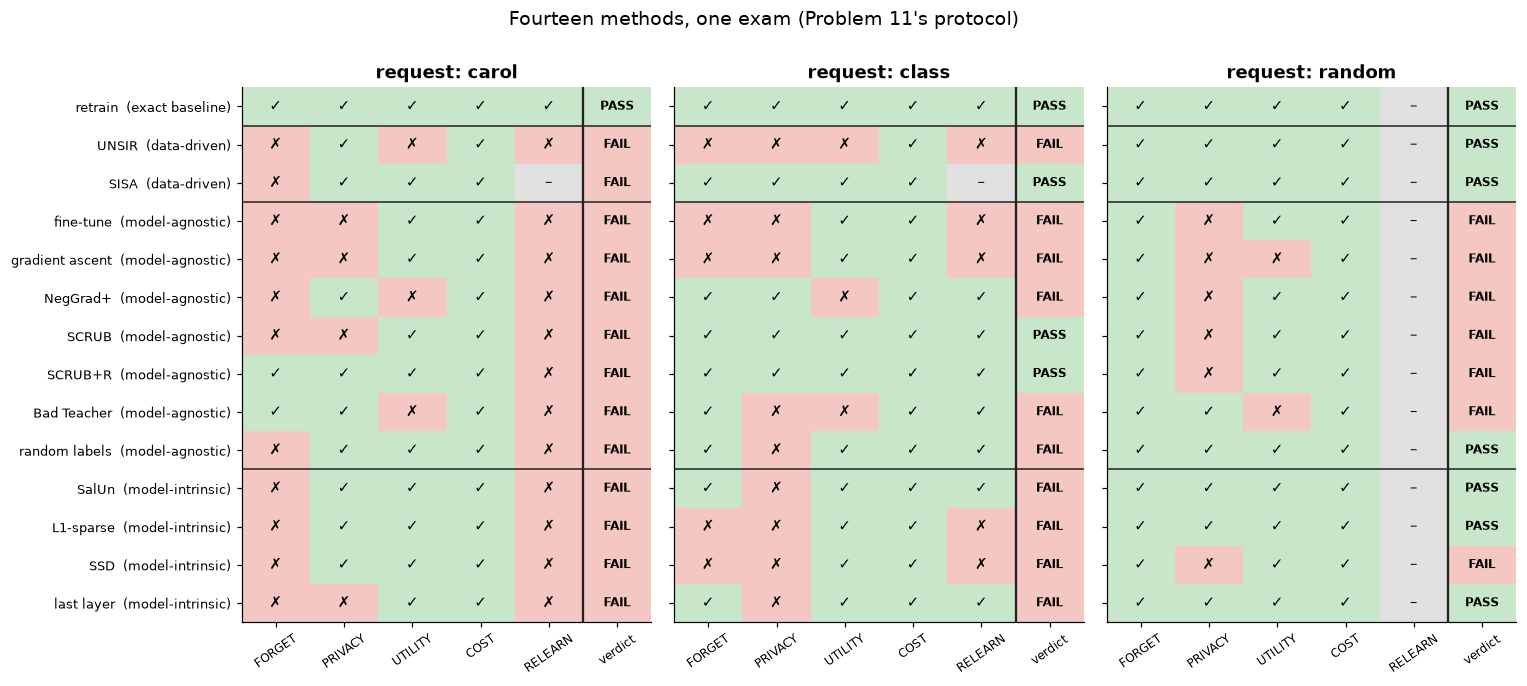

                          family carol class random  cost (% of retrain, carol)
method                                                                         
retrain           exact baseline  PASS  PASS   PASS                       100.0
UNSIR                data-driven  FAIL  FAIL   PASS                        12.2
SISA                 data-driven  FAIL  PASS   PASS                        61.4
fine-tune         model-agnostic  FAIL  FAIL   FAIL                         8.3
gradient ascent   model-agnostic  FAIL  FAIL   FAIL                         0.3
NegGrad+          model-agnostic  FAIL  FAIL   FAIL                         8.6
SCRUB             model-agnostic  FAIL  PASS   FAIL                        13.6
SCRUB+R           model-agnostic  FAIL  PASS   FAIL                        13.6
Bad Teacher       model-agnostic  FAIL  FAIL   FAIL                         0.6
random labels     model-agnostic  FAIL  FAIL   PASS                         8.6
SalUn            model-intrinsic  FAIL  

In [5]:
# Step 4: the verdict map - which check does each method fail, on which request? Rows grouped by family.
checks = ["FORGET", "PRIVACY", "UTILITY", "COST", "RELEARN", "verdict"]
order = sorted([m for m in R["carol"]["table"].index if m != "original"],
               key=lambda m: (["exact baseline", "data-driven", "model-agnostic", "model-intrinsic"].index(FAMILY[m]), m != "retrain"))
fig, axes = plt.subplots(1, 3, figsize=(14, 6.2), sharey=True)
for ax, (scen, r) in zip(axes, R.items()):
    t = r["table"].loc[order, checks].replace({"ok": 1.0, "ref": 1.0, "PASS": 1.0, "x": 0.0, "FAIL": 0.0, "n/a": 0.5}).astype(float)
    ax.imshow(t.values, cmap=ListedColormap(["#f4c7c3", "#e0e0e0", "#c8e6c9"]), vmin=0, vmax=1, aspect="auto")
    for i in range(len(order)):
        for j in range(len(checks)):
            mark = {1.0: "✓", 0.5: "–", 0.0: "✗"}[t.values[i, j]] if j < 5 else ("PASS" if t.values[i, j] else "FAIL")
            ax.text(j, i, mark, ha="center", va="center", fontsize=10 if j < 5 else 8, fontweight="bold" if j == 5 else None)
    ax.axvline(4.5, color=viz.INK, lw=1.5)
    for i in range(1, len(order)):
        if FAMILY[order[i]] != FAMILY[order[i - 1]]:
            ax.axhline(i - 0.5, color=viz.INK, lw=1)
    ax.set_xticks(range(len(checks))); ax.set_xticklabels(checks, rotation=35, fontsize=8)
    ax.set_yticks(range(len(order))); ax.set_yticklabels([f"{m}  ({FAMILY[m]})" for m in order], fontsize=8.5); ax.grid(False)
    ax.set_title(f"request: {scen}")
plt.suptitle("Fourteen methods, one exam (Problem 11's protocol)", y=1.0); plt.tight_layout(); plt.show()

board = pd.DataFrame({scen: r["table"].loc[order, "verdict"] for scen, r in R.items()})
board.insert(0, "family", [FAMILY[m] for m in order])
board["cost (% of retrain, carol)"] = R["carol"]["table"].loc[order, "cost_%"].round(1)
print(board.to_string())

Read the map row by row.

- **Carol (one person, memorised) : only the exact methods have a chance.** Retrain passes. Every approximate method,
  old or new, fails, and every one of them fails **RELEARN** : show it half of Carol's digits for a few steps and it is
  right about the other half again. SISA misses FORGET by a hair, the same false alarm Problem 11 explained.
- **The class (every digit 3) :** SCRUB and SCRUB+R still pass, as in Problem 11, and so does SISA. Random labels and
  SalUn remove the class but fail PRIVACY. **UNSIR and SSD do nothing at all** here.
- **Random 10% :** five of the six new methods pass. In Problem 11 nothing approximate passed this request.

Two of those surprises have simple explanations.

**SSD changed no weights on the class request** (the share is printed above Step 4). Its rule only touches a weight if
it matters more than `alpha = 10` times as much for the forget data as for the *whole* training set. But the whole
training set *includes* the forget data. If the forget data is 10% of it, a weight's importance for the whole set is at
least 10% of its importance for the forget data. So the rule can never fire. With `alpha = 10`, SSD is built for
small forget sets (the paper's own class tasks forget between 1% and 5% of the data).

**UNSIR left the class untouched.** Its noise images and one short impair step, at the pre-registered settings, were
not strong enough to break what the model knows about 3s. That is the cost of pre-registering : no method gets tuned on
the answer sheet.

The third surprise, the random request, needs a closer look.

#### Step 5 : Prove it - are the new passes real ?

**Stop and notice what just happened.** Look at the PRIVACY column for L1-sparse on Carol. It *passes*, even though it
still gets all 40 of Carol's digits right (FORGET fails). How can a model that remembers Carol perfectly look like a model
that never saw her?

U-LiRA (Problem 5) looks at the model's **confidence** on each forget example and asks : is this confidence more like
the models that saw it, or more like the models that never did? Let's look at confidence on the data the model is
supposed to *keep*, where nothing should change.

In [6]:
# Step 5a: average confidence in the right answer, on data the model KEEPS (random request)
r, L = R["random"], R["random"]["L"]
conf = lambda m, X, y: float(np.mean(train.predict_proba(m, X)[np.arange(len(y)), y]))
log_odds = lambda p: np.log(p / (1 - p))
show = ["original", "retrain", "SCRUB", "random labels", "SalUn", "L1-sparse", "UNSIR", "last layer"]
c = pd.DataFrame({"confidence on kept data": [conf(r["models"][m], L.Xr, L.yr) for m in show]}, index=show)
c["as log-odds (what U-LiRA uses)"] = log_odds(c["confidence on kept data"])
print(c.round(3).to_string())

               confidence on kept data  as log-odds (what U-LiRA uses)
original                         1.000                           7.650
retrain                          0.999                           7.143
SCRUB                            0.999                           7.113
random labels                    0.884                           2.035
SalUn                            0.874                           1.939
L1-sparse                        0.983                           4.046
UNSIR                            0.957                           3.093
last layer                       0.997                           5.984


The new methods that "passed" make the model **less sure about almost everything**, including data it should keep.
On a 0-1 scale the drop looks small. But U-LiRA works with log-odds, where being 99.9% sure and 98% sure are far apart.
To U-LiRA, lower confidence looks like "never saw it", whether or not the specific forget example was removed. (The
last-layer re-solve moves the least; its new last layer is regularised, which nudges confidence down a little.)

This is the **recipe trap** from Problems 7 and 11 again : the reference models must be made the same way as the model
under test. Problem 11 fixed it for SISA. Here we fix it for every method, the way Hayes et al. (2024) do : apply the
method to the reference models too.

- IN references : models that saw the data, **then** put through the method;
- OUT references : models that never saw the data, **then** put through the same method;
- a **control** : one more never-saw-it model put through the method. The test should call it "not a member". Its
  score is the false-alarm level.

If the method really removes the forget data, the unlearned model looks like the OUT group. If it only lowers
confidence, both groups move together and the unlearned model still looks like the IN group.

=== random   (share of forget examples the test calls 'still a member'; lower is better)
                 standard U-LiRA  own-recipe U-LiRA  control (never saw it) own-recipe PRIVACY
fine-tune                  0.728              0.672                   0.304                  x
gradient ascent            0.512              0.672                   0.208                  x
NegGrad+                   0.632              0.856                   0.376                  x
SCRUB                      0.592              0.720                   0.392                  x
SCRUB+R                    0.520              0.648                   0.552                 ok
Bad Teacher                0.392              0.592                   0.384                  x
random labels              0.296              0.584                   0.408                  x
SalUn                      0.296              0.616                   0.376                  x
L1-sparse                  0.272              0.712     

=== carol   (share of forget examples the test calls 'still a member'; lower is better)
                 standard U-LiRA  own-recipe U-LiRA  control (never saw it) own-recipe PRIVACY
fine-tune                  0.875              0.925                   0.100                  x
gradient ascent            0.600              0.925                   0.050                  x
NegGrad+                   0.000              0.750                   0.450                  x
SCRUB                      0.275              0.975                   0.350                  x
SCRUB+R                    0.125              0.925                   0.300                  x
Bad Teacher                0.150              0.850                   0.275                  x
random labels              0.000              0.675                   0.350                  x
SalUn                      0.000              0.675                   0.300                  x
L1-sparse                  0.050              0.700      

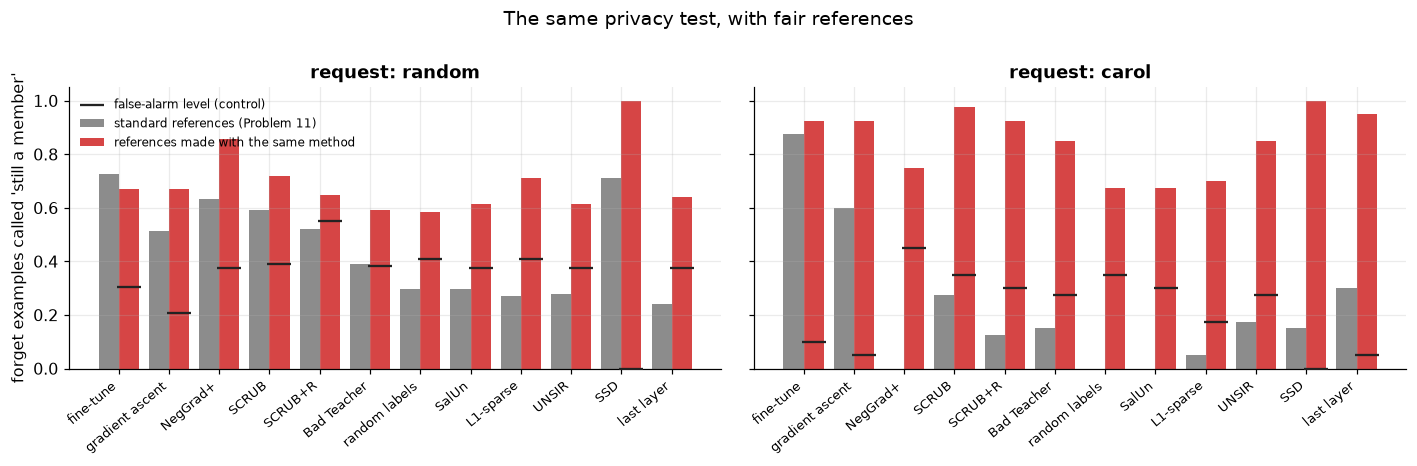

In [7]:
# Step 5b: U-LiRA with references built by the SAME method ("own recipe"), on the random request and on Carol
CHECK = ["fine-tune", "gradient ascent", "NegGrad+", "SCRUB", "SCRUB+R", "Bad Teacher",
         "random labels", "SalUn", "L1-sparse", "UNSIR", "SSD", "last layer"]
own = {}
for scen in ["random", "carol"]:
    r, L = R[scen], R[scen]["L"]
    control_base = mono(L.Xr, L.yr, 999)                               # one more model that never saw the forget data
    rows = {}
    for name in CHECK:
        IN2 = [unlearn(name, m, L)[0] for m in r["IN"]]
        OUT2 = [unlearn(name, m, L)[0] for m in r["OUT"]]
        rows[name] = {"standard U-LiRA": r["table"].loc[name, "ulira"],
                      "own-recipe U-LiRA": audit.ulira(r["models"][name], L.Xf, L.yf, IN2, OUT2),
                      "control (never saw it)": audit.ulira(unlearn(name, control_base, L)[0], L.Xf, L.yf, IN2, OUT2)}
    own[scen] = pd.DataFrame(rows).T
    own[scen]["own-recipe PRIVACY"] = np.where(own[scen]["own-recipe U-LiRA"] <= own[scen]["control (never saw it)"] + PROTOCOL["gate"]["privacy_tol"], "ok", "x")
    print(f"=== {scen}   (share of forget examples the test calls 'still a member'; lower is better)")
    print(own[scen].round(3).to_string()); print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, scen in zip(axes, ["random", "carol"]):
    t = own[scen]; x = np.arange(len(t))
    ax.bar(x - 0.2, t["standard U-LiRA"], 0.4, color=viz.ORIGINAL, label="standard references (Problem 11)")
    ax.bar(x + 0.2, t["own-recipe U-LiRA"], 0.4, color=viz.FORGET, label="references made with the same method")
    ax.scatter(x + 0.2, t["control (never saw it)"], marker="_", s=250, color=viz.INK, zorder=3, label="false-alarm level (control)")
    ax.set_xticks(x); ax.set_xticklabels(t.index, rotation=40, ha="right", fontsize=8.5)
    ax.set_ylim(0, 1.05); ax.set_title(f"request: {scen}")
axes[0].set_ylabel("forget examples called 'still a member'"); axes[0].legend(fontsize=8, loc="upper left")
plt.suptitle("The same privacy test, with fair references", y=1.0); plt.tight_layout(); plt.show()

**Read that again.** With references made the fair way, the approximate methods are called "still a member" on far
more forget examples than the never-saw-it control. On Carol that is true for every one of them. On the random request
it is true for every one except SCRUB+R, and there the control itself is called a member about half the time, so the
test is too noisy to say anything (and SCRUB+R already failed the exam on that request). The five passes on the random
request came from the shortcut, not from forgetting.

This also corrects Problem 11. There, SCRUB+R passed PRIVACY on Carol with the standard references. With references made
the fair way it fails too. Problem 11's final verdict for SCRUB+R on Carol was already FAIL (because of RELEARN), so the
conclusion does not change, but its privacy check was too easy on every approximate method. The lesson generalises :
**any change to how a model is made, including the unlearning method itself, is part of the recipe.**

We do not run this check on the class request. There, a method that wipes out the class makes the IN and OUT groups
identical (both get every 3 wrong), so the test has nothing to compare, and even its control scores as a member. The
standard result stands for that request.

Now the final leaderboard, with the fair privacy check folded in, written to `results/leaderboard.json`.

In [8]:
# Step 5c: the final leaderboard - a method passes only if it passes the exam AND the fair privacy check (where run)
final = {}
for scen, r in R.items():
    v = r["table"]["verdict"].copy()
    if scen in own:
        fair = own[scen]["own-recipe PRIVACY"]
        v[fair.index] = np.where((v[fair.index] == "PASS") & (fair == "ok"), "PASS", "FAIL")
    final[scen] = v
leaderboard = pd.DataFrame({"family": [FAMILY[m] for m in order], "data type": "image (8x8 digits)",
                            **{s: final[s][order] for s in R},
                            "cost (% of retrain)": R["carol"]["table"].loc[order, "cost_%"].round(1)}, index=order)
leaderboard["passes"] = (leaderboard[list(R)] == "PASS").sum(axis=1)
print(leaderboard.sort_values("passes", ascending=False, kind="stable").to_string())

os.makedirs("results", exist_ok=True)
record = dict(dataset="sklearn digits (8x8)", model="MLP 64-256-256-10", protocol=PROTOCOL, families=FAMILY,
              family_source="Nguyen et al. 2022, 'A Survey of Machine Unlearning' (methods not named there tagged by the same rule)",
              fair_privacy_check="U-LiRA with references put through the same method (Hayes et al. 2024); run on carol and random",
              leaderboard=json.loads(leaderboard.to_json(orient="index")),
              audits={s: json.loads(r["table"][["forget_acc", "test_acc", "ulira", "relearn_steps", "cost_%",
                                                 "FORGET", "PRIVACY", "UTILITY", "COST", "RELEARN", "verdict"]].to_json(orient="index"))
                      for s, r in R.items()},
              fair_privacy={s: json.loads(t.to_json(orient="index")) for s, t in own.items()})
with open("results/leaderboard.json", "w") as f:
    json.dump(record, f, indent=1)
print("\nwritten: results/leaderboard.json")

                          family           data type carol class random  cost (% of retrain)  passes
retrain           exact baseline  image (8x8 digits)  PASS  PASS   PASS                100.0       3
SISA                 data-driven  image (8x8 digits)  FAIL  PASS   PASS                 61.4       2
SCRUB             model-agnostic  image (8x8 digits)  FAIL  PASS   FAIL                 13.6       1
SCRUB+R           model-agnostic  image (8x8 digits)  FAIL  PASS   FAIL                 13.6       1
UNSIR                data-driven  image (8x8 digits)  FAIL  FAIL   FAIL                 12.2       0
fine-tune         model-agnostic  image (8x8 digits)  FAIL  FAIL   FAIL                  8.3       0
gradient ascent   model-agnostic  image (8x8 digits)  FAIL  FAIL   FAIL                  0.3       0
NegGrad+          model-agnostic  image (8x8 digits)  FAIL  FAIL   FAIL                  8.6       0
Bad Teacher       model-agnostic  image (8x8 digits)  FAIL  FAIL   FAIL                  0.

----
#### OUTCOME :

| family | methods | carol | class | random |
|---|---|---|---|---|
| exact baseline | retrain | ✅ | ✅ | ✅ |
| data-driven | SISA | ⚠️ false alarm (Problem 11) | ✅ | ✅ |
| data-driven | UNSIR | ❌ | ❌ does nothing | ❌ (pass was not real) |
| model-agnostic | fine-tune, gradient ascent, NegGrad+, Bad Teacher | ❌ | ❌ | ❌ |
| model-agnostic | SCRUB, SCRUB+R | ❌ relearns | ✅ | ❌ |
| model-agnostic | random labels | ❌ relearns | ❌ privacy | ❌ (pass was not real) |
| model-intrinsic | SalUn, L1-sparse, last layer | ❌ | ❌ | ❌ (pass was not real) |
| model-intrinsic | SSD | ❌ relearns | ❌ cannot fire | ❌ |

#### Key Takeaways :

- **New is not the same as better.** Six newer methods, run with their papers' default settings on a fixed exam, did
  not beat the old ones. No approximate method forgot Carol.
- **The family does not decide the result.** Each family has methods that pass something and methods that fail
  everything. What decides it is the request (one person, a class, a random sample) and the exam.
- **Read the rule before you trust the method.** SSD's rule cannot fire when the forget set is 10% of the data or more.
- **A privacy test can be fooled by accident.** Lowering confidence everywhere looks like forgetting to U-LiRA. Build
  the reference models with the same method you are testing, and add a never-saw-it control.
- The exact methods (retrain, SISA, and the classical updates of Problems 1-3) remain the only ones that pass by
  design.

#### TASK :
1. Give SSD a fair chance on the class request : find the smallest `alpha` that changes any weights, then the `alpha`
   that removes the class. Does it keep UTILITY? (You are now tuning on the answer sheet. Say so in your notes.)
2. Raise UNSIR's strength (more noise steps, a larger impair learning rate) until it removes the class. What does that
   cost in UTILITY and in time?
3. Run the fair privacy check of Step 5 for SISA on Carol. You will need SISA references put through SISA's own
   unlearning. Does the "false alarm" from Problem 11 survive?
4. Add a fifteenth method of your own (for example, gradient ascent on only the last layer). Run it through the same
   exam, without changing the protocol.

#### ❓ Open question → Problem 20
Everything so far ran on 1,797 small digit images. **Do these rankings, the memorisation of Carol and the cost ratios
still hold when the data is 50 times larger and the model is a real convolutional network?** That is Problem 20.